*  DSC530-T301 Data Exploration and Analysis (2263-1)
*  Week 11 Final Project
*  David Jorgensen

# NYC Tree Census Analysis: Identifying Degradation Across City Sectors
## Comprehensive Exploratory Data Analysis

This notebook investigates tree health degradation across New York City sectors using tree census data from 1995, 2005, and 2015 to identify patterns and trends in tree health.

In [15]:
# Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, spearmanr, kendalltau, kruskal
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, 
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, silhouette_score)
from sklearn.model_selection import train_test_split, cross_val_score
import warnings
warnings.filterwarnings('ignore')

# Set visualization parameters
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


## Section 1: Data Loading and Initial Exploration

In [16]:
# Load census data for all three years
data_path = './final-project-data/'

census_1995 = pd.read_csv(f'{data_path}new_york_tree_census_1995.csv')
census_2005 = pd.read_csv(f'{data_path}new_york_tree_census_2005.csv')
census_2015 = pd.read_csv(f'{data_path}new_york_tree_census_2015.csv')
species_info = pd.read_csv(f'{data_path}new_york_tree_species.csv')

# Add year column to identify time period
census_1995['census_year'] = 1995
census_2005['census_year'] = 2005
census_2015['census_year'] = 2015

# Combine all census data
combined_data = pd.concat([census_1995, census_2005, census_2015], ignore_index=True)

print("✓ Data loaded successfully!")
print(f"\nDataset Shapes:")
print(f"  1995 Census: {census_1995.shape}")
print(f"  2005 Census: {census_2005.shape}")
print(f"  2015 Census: {census_2015.shape}")
print(f"  Combined Data: {combined_data.shape}")
print(f"  Species Info: {species_info.shape}")

print(f"\n1995 Data Shape: {census_1995.shape}")
print("\nFirst few rows of 1995 Census:")
print(census_1995.head())

print(f"\n2015 Data Shape: {census_2015.shape}")
print("\nFirst few rows of 2015 Census:")
print(census_2015.head())

✓ Data loaded successfully!

Dataset Shapes:
  1995 Census: (516989, 28)
  2005 Census: (1777116, 48)
  2015 Census: (683788, 42)
  Combined Data: (2977893, 93)
  Species Info: (57, 10)

1995 Data Shape: (516989, 28)

First few rows of 1995 Census:
   recordid          address house_number        street  zip_original  \
0    433600     73-031 57 AV       73-031         57 AV         11378   
1     48050  2434 HOFFMAN ST         2434    HOFFMAN ST         10458   
2    506340  33 MULBERRY CIR           33  MULBERRY CIR         10314   
3    348044    79-037 213 ST       79-037        213 ST         11364   
4    354765    68-015 172 ST       68-015        172 ST         11365   

   cb_original      site species  diameter     status  ... cb_new zip_new  \
0          405     Front    QUPA         6       Good  ...    405   11378   
1          106  Adjacent    GLTR        10  Excellent  ...    206   10458   
2          502     Front    QURU        21       Good  ...    502   10314   
3   

In [17]:
# Examine column names across datasets
print("Column Names in 1995 Census:")
print(list(census_1995.columns))
print("\n" + "="*80 + "\n")

print("Column Names in 2015 Census:")
print(list(census_2015.columns))
print("\n" + "="*80 + "\n")

# Identify common columns
common_cols = set(census_1995.columns) & set(census_2005.columns) & set(census_2015.columns)
print(f"Common columns across all datasets ({len(common_cols)} columns):")
print(sorted(common_cols))

# Data type information
print("\n" + "="*80 + "\n")
print("Data types in 2015 Census:")
print(census_2015.dtypes)

Column Names in 1995 Census:
['recordid', 'address', 'house_number', 'street', 'zip_original', 'cb_original', 'site', 'species', 'diameter', 'status', 'wires', 'sidewalk_condition', 'support_structure', 'borough', 'x', 'y', 'longitude', 'latitude', 'cb_new', 'zip_new', 'censustract_2010', 'censusblock_2010', 'nta_2010', 'segmentid', 'spc_common', 'spc_latin', 'location', 'census_year']


Column Names in 2015 Census:
['tree_id', 'block_id', 'created_at', 'tree_dbh', 'stump_diam', 'curb_loc', 'status', 'health', 'spc_latin', 'spc_common', 'steward', 'guards', 'sidewalk', 'user_type', 'problems', 'root_stone', 'root_grate', 'root_other', 'trunk_wire', 'trnk_light', 'trnk_other', 'brch_light', 'brch_shoe', 'brch_other', 'address', 'zipcode', 'zip_city', 'cb_num', 'borocode', 'boroname', 'cncldist', 'st_assem', 'st_senate', 'nta', 'nta_name', 'boro_ct', 'state', 'latitude', 'longitude', 'x_sp', 'y_sp', 'census_year']


Common columns across all datasets (4 columns):
['census_year', 'spc_com

In [18]:
# Data Cleaning and Preparation
# Focus on 2015 data for detailed analysis (most complete)
df = census_2015.copy()

print("Missing Values in 2015 Census:")
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing_Count': missing[missing > 0], 'Percentage': missing_pct[missing_pct > 0]})
print(missing_df.sort_values('Missing_Count', ascending=False))

print(f"\nTotal records: {len(df)}")
print(f"Date range: {df['created_at'].min()} to {df['created_at'].max()}")

# Focus on key columns for analysis
key_columns = ['tree_id', 'tree_dbh', 'status', 'health', 'boroname', 'spc_common', 
               'spc_latin', 'zipcode', 'problems', 'steward', 'guards', 'nta_name', 'boro_ct']

# Examine unique values in categorical columns
print("\nUnique Values in Key Categorical Columns:")
print(f"Status values: {df['status'].unique()}")
print(f"Health values: {df['health'].unique()}")
print(f"Borough values: {df['boroname'].unique()}")
print(f"Number of tree species: {df['spc_common'].nunique()}")
print(f"Number of neighborhoods (NTA): {df['nta_name'].nunique()}")

Missing Values in 2015 Census:
            Missing_Count  Percentage
guards             603922       88.32
steward            519438       75.96
problems           457944       66.97
spc_latin           31619        4.62
spc_common          31619        4.62
health              31616        4.62
sidewalk            31616        4.62

Total records: 683788
Date range: 2015-05-19 to 2016-10-05

Unique Values in Key Categorical Columns:
Status values: ['Alive' 'Dead' 'Stump']
Health values: ['Good' 'Fair' nan 'Poor']
Borough values: ['Queens' 'Brooklyn' 'Manhattan' 'Bronx' 'Staten Island']
Number of tree species: 132
Number of neighborhoods (NTA): 188


## Section 2: Variable Characteristics and Summary Statistics

In [19]:
# Summary Statistics for Numerical Variables
print("DESCRIPTIVE STATISTICS FOR NUMERICAL VARIABLES")
print("=" * 80)

numerical_cols = ['tree_dbh', 'latitude', 'longitude']
numerical_subset = df[numerical_cols].copy()

# Remove invalid values
numerical_subset['tree_dbh'] = pd.to_numeric(df['tree_dbh'], errors='coerce')

summary_stats = numerical_subset.describe().round(3)
print("\nBasic Descriptive Statistics:")
print(summary_stats)

# Additional statistical measures
print("\n\nAdditional Statistical Measures:")
stats_dict = {}
for col in numerical_cols:
    stats_dict[col] = {
        'Skewness': stats.skew(numerical_subset[col].dropna()),
        'Kurtosis': stats.kurtosis(numerical_subset[col].dropna()),
        'Std Dev': numerical_subset[col].std(),
        'Coeff. Variation': (numerical_subset[col].std() / numerical_subset[col].mean() * 100)
    }

print(f"{'Measure':<20} {'tree_dbh':<15} {'latitude':<15} {'longitude':<15}")
print("-" * 65)
for measure in ['Skewness', 'Kurtosis', 'Std Dev', 'Coeff. Variation']:
    values = []
    for col in numerical_cols:
        val = stats_dict[col][measure]
        if measure == 'Coeff. Variation':
            values.append(f"{val:.3f}%")
        else:
            values.append(f"{val:.3f}")
    print(f"{measure:<20} {values[0]:<15} {values[1]:<15} {values[2]:<15}")

# Categorical variable summary
print("\n\n" + "=" * 80)
print("CATEGORICAL VARIABLE SUMMARY")
print("=" * 80)

categorical_vars = ['status', 'health', 'boroname', 'steward', 'guards']
for var in categorical_vars:
    if var in df.columns:
        print(f"\n{var.upper()} Distribution:")
        value_counts = df[var].value_counts()
        value_pct = (df[var].value_counts(normalize=True) * 100).round(2)
        freq_table = pd.DataFrame({'Count': value_counts, 'Percentage': value_pct})
        print(freq_table)
        print(f"Mode: {df[var].mode()[0]}")

DESCRIPTIVE STATISTICS FOR NUMERICAL VARIABLES



Basic Descriptive Statistics:
         tree_dbh    latitude   longitude
count  683788.000  683788.000  683788.000
mean       11.280      40.701     -73.924
std         8.723       0.090       0.124
min         0.000      40.498     -74.255
25%         4.000      40.632     -73.981
50%         9.000      40.701     -73.913
75%        16.000      40.762     -73.835
max       450.000      40.913     -73.700


Additional Statistical Measures:
Measure              tree_dbh        latitude        longitude      
-----------------------------------------------------------------
Skewness             2.429           0.063           -0.612         
Kurtosis             46.977          -0.634          -0.119         
Std Dev              8.723           0.090           0.124          
Coeff. Variation     77.333%         0.222%          -0.167%        


CATEGORICAL VARIABLE SUMMARY

STATUS Distribution:
         Count  Percentage
status                    
Alive   652173       95.38
Stump    17

## Section 3: Univariate Analysis

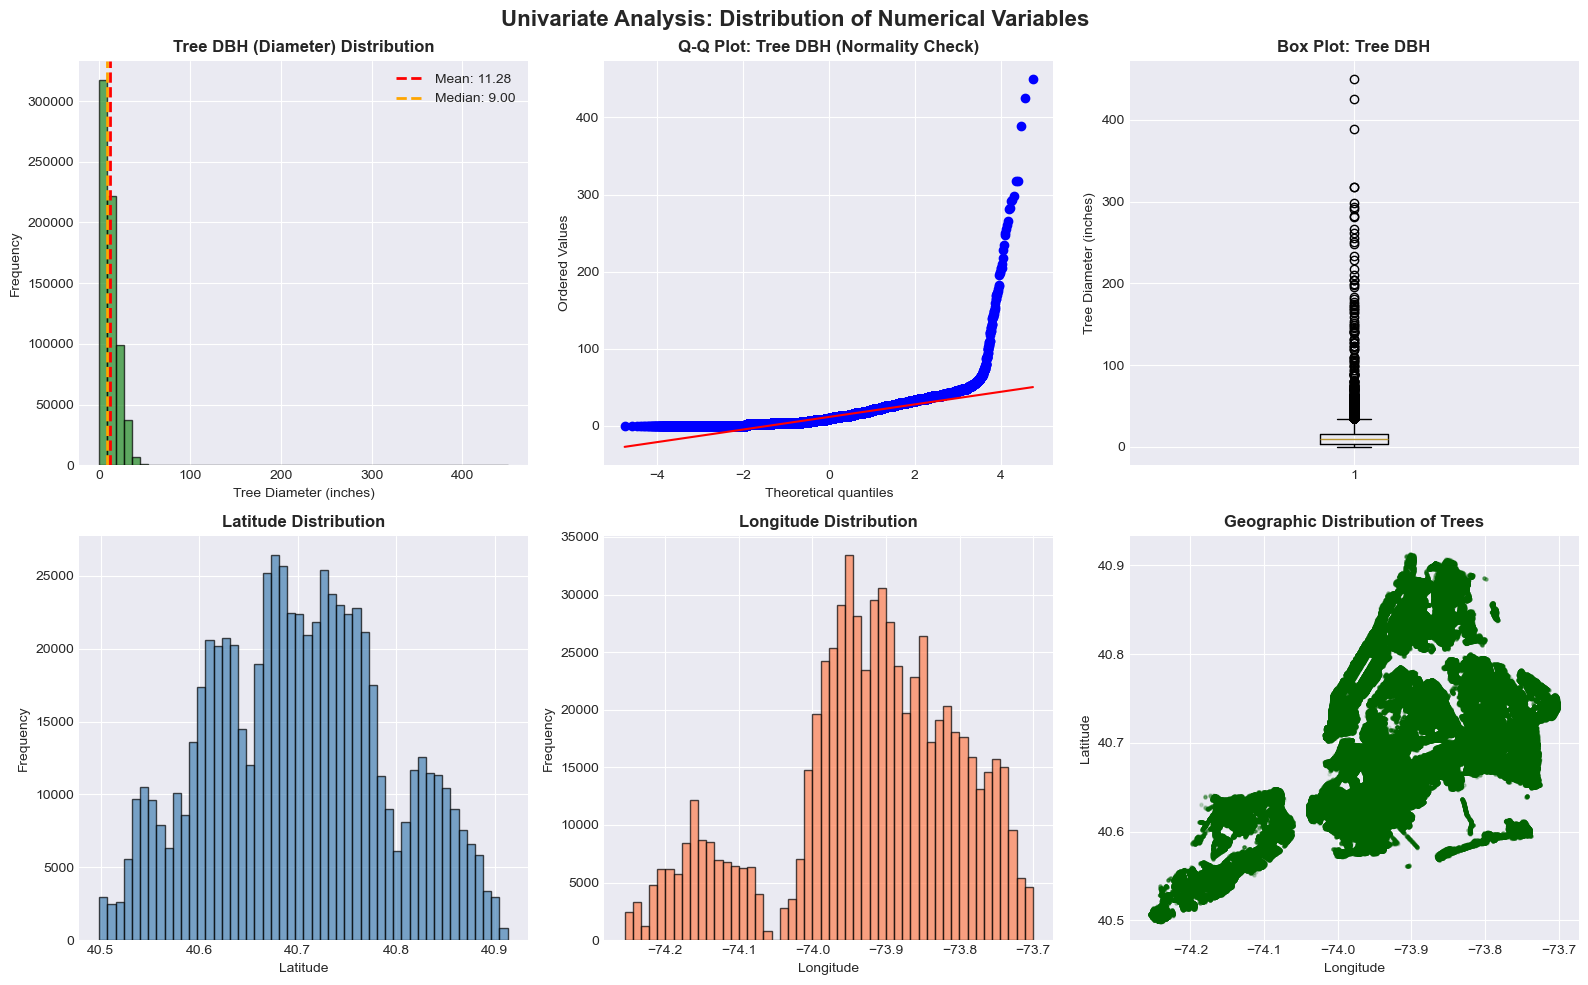

✓ Univariate numerical analysis visualizations complete


In [20]:
# Univariate Analysis - Numerical Variables Visualization
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Univariate Analysis: Distribution of Numerical Variables', fontsize=16, fontweight='bold')

# Tree DBH Distribution
tree_dbh_clean = pd.to_numeric(df['tree_dbh'], errors='coerce').dropna()
axes[0, 0].hist(tree_dbh_clean, bins=50, color='forestgreen', edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Tree DBH (Diameter) Distribution', fontweight='bold')
axes[0, 0].set_xlabel('Tree Diameter (inches)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].axvline(tree_dbh_clean.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {tree_dbh_clean.mean():.2f}')
axes[0, 0].axvline(tree_dbh_clean.median(), color='orange', linestyle='--', linewidth=2, label=f'Median: {tree_dbh_clean.median():.2f}')
axes[0, 0].legend()

# Q-Q plot for tree DBH
stats.probplot(tree_dbh_clean, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title('Q-Q Plot: Tree DBH (Normality Check)', fontweight='bold')

# Box plot for tree DBH
axes[0, 2].boxplot(tree_dbh_clean, vert=True)
axes[0, 2].set_title('Box Plot: Tree DBH', fontweight='bold')
axes[0, 2].set_ylabel('Tree Diameter (inches)')

# Latitude Distribution
axes[1, 0].hist(df['latitude'].dropna(), bins=50, color='steelblue', edgecolor='black', alpha=0.7)
axes[1, 0].set_title('Latitude Distribution', fontweight='bold')
axes[1, 0].set_xlabel('Latitude')
axes[1, 0].set_ylabel('Frequency')

# Longitude Distribution
axes[1, 1].hist(df['longitude'].dropna(), bins=50, color='coral', edgecolor='black', alpha=0.7)
axes[1, 1].set_title('Longitude Distribution', fontweight='bold')
axes[1, 1].set_xlabel('Longitude')
axes[1, 1].set_ylabel('Frequency')

# Scatter plot of lat/long
axes[1, 2].scatter(df['longitude'].dropna(), df['latitude'].dropna(), alpha=0.1, s=5, color='darkgreen')
axes[1, 2].set_title('Geographic Distribution of Trees', fontweight='bold')
axes[1, 2].set_xlabel('Longitude')
axes[1, 2].set_ylabel('Latitude')

plt.tight_layout()
plt.show()

print("✓ Univariate numerical analysis visualizations complete")

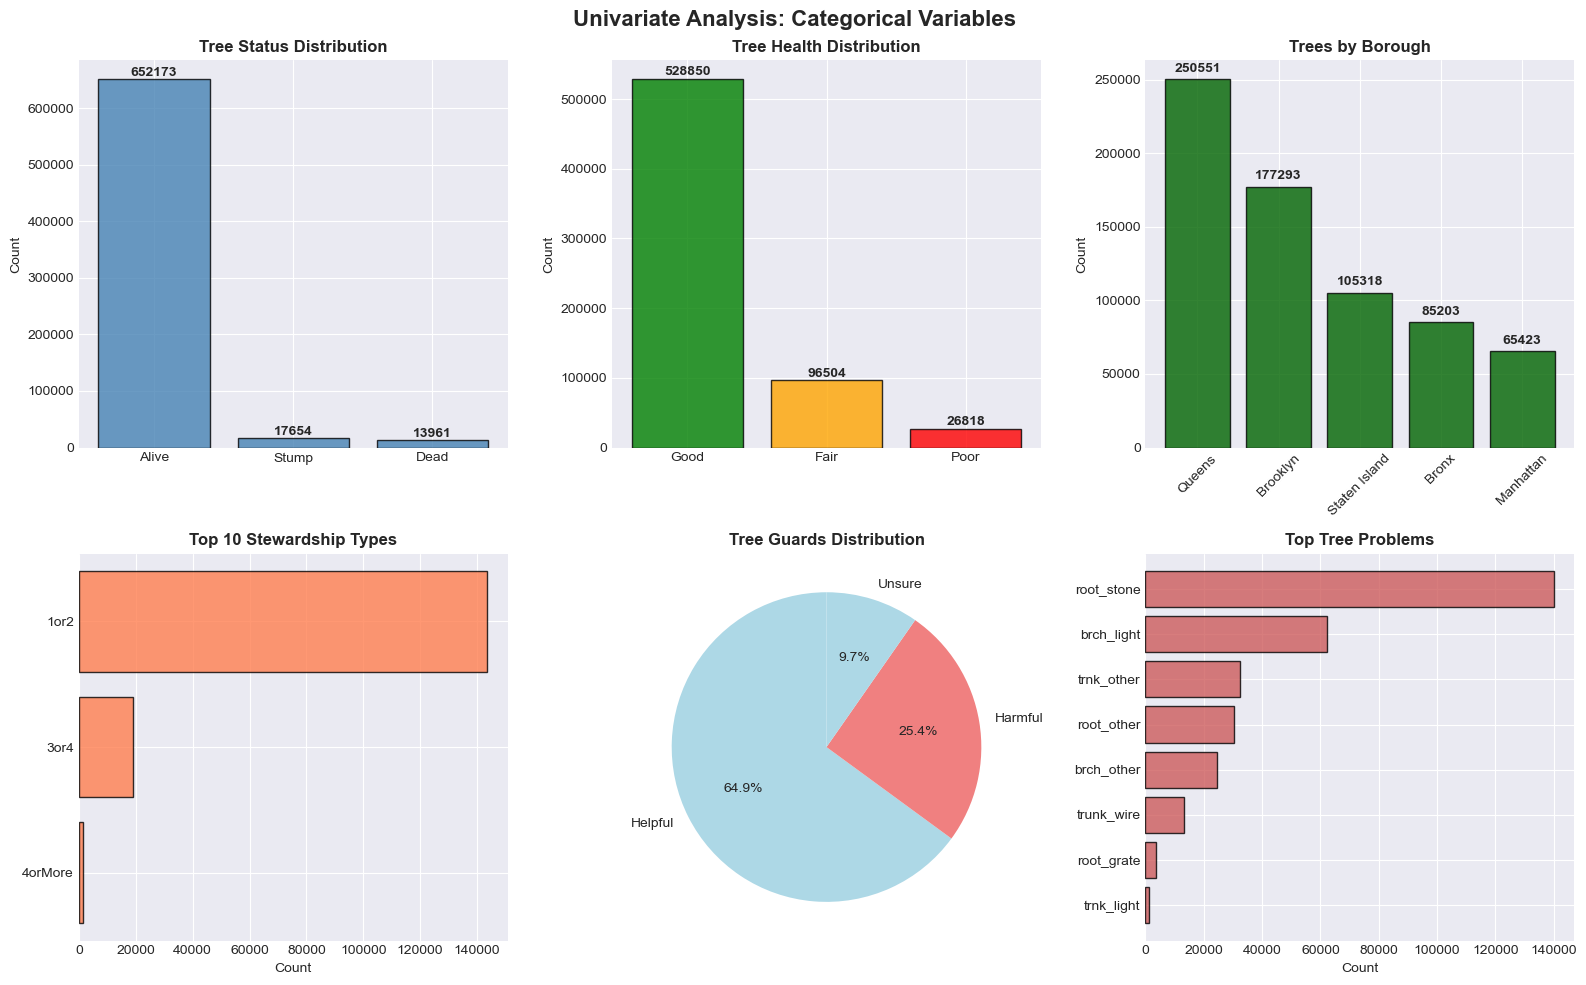

Univariate categorical analysis visualizations complete


In [21]:
# Univariate Analysis - Categorical Variables
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Univariate Analysis: Categorical Variables', fontsize=16, fontweight='bold')

# Status Distribution
status_counts = df['status'].value_counts()
axes[0, 0].bar(status_counts.index, status_counts.values, color='steelblue', alpha=0.8, edgecolor='black')
axes[0, 0].set_title('Tree Status Distribution', fontweight='bold')
axes[0, 0].set_ylabel('Count')
for i, v in enumerate(status_counts.values):
    axes[0, 0].text(i, v + 5000, str(v), ha='center', fontweight='bold')

# Health Distribution
health_order = ['Good', 'Fair', 'Poor']
health_counts = df['health'].value_counts().reindex([h for h in health_order if h in df['health'].values])
colors_health = ['green', 'orange', 'red']
axes[0, 1].bar(health_counts.index, health_counts.values, color=colors_health[:len(health_counts)], alpha=0.8, edgecolor='black')
axes[0, 1].set_title('Tree Health Distribution', fontweight='bold')
axes[0, 1].set_ylabel('Count')
for i, v in enumerate(health_counts.values):
    axes[0, 1].text(i, v + 5000, str(v), ha='center', fontweight='bold')

# Borough Distribution
boro_counts = df['boroname'].value_counts()
axes[0, 2].bar(boro_counts.index, boro_counts.values, color='darkgreen', alpha=0.8, edgecolor='black')
axes[0, 2].set_title('Trees by Borough', fontweight='bold')
axes[0, 2].set_ylabel('Count')
axes[0, 2].tick_params(axis='x', rotation=45)
for i, v in enumerate(boro_counts.values):
    axes[0, 2].text(i, v + 5000, str(v), ha='center', fontweight='bold')

# Steward Distribution (Top 10)
steward_counts = df['steward'].value_counts().head(10)
axes[1, 0].barh(steward_counts.index, steward_counts.values, color='coral', alpha=0.8, edgecolor='black')
axes[1, 0].set_title('Top 10 Stewardship Types', fontweight='bold')
axes[1, 0].set_xlabel('Count')
axes[1, 0].invert_yaxis()

# Guards Distribution
guards_counts = df['guards'].value_counts()
axes[1, 1].pie(guards_counts.values, labels=guards_counts.index, autopct='%1.1f%%', 
               colors=['lightblue', 'lightcoral'], startangle=90)
axes[1, 1].set_title('Tree Guards Distribution', fontweight='bold')

# Problems Distribution (Top 10)
# Create problem categories
problem_cols = ['root_stone', 'root_grate', 'root_other', 'trunk_wire', 'trnk_light', 
                'trnk_other', 'brch_light', 'brch_shoe', 'brch_other']
problem_counts = {}
for col in problem_cols:
    if col in df.columns:
        problem_counts[col] = (df[col] == 'Yes').sum()

# Visualize top problems
if problem_counts:
    problem_df = pd.Series(problem_counts).sort_values(ascending=False).head(8)
    axes[1, 2].barh(problem_df.index, problem_df.values, color='indianred', alpha=0.8, edgecolor='black')
    axes[1, 2].set_title('Top Tree Problems', fontweight='bold')
    axes[1, 2].set_xlabel('Count')
    axes[1, 2].invert_yaxis()

plt.tight_layout()
plt.show()

print("Univariate categorical analysis visualizations complete")

## Section 4: Bivariate Analysis

In [22]:
# Bivariate Analysis: Categorical Variables Relationships
print("BIVARIATE ANALYSIS: CATEGORICAL RELATIONSHIPS")
print("=" * 80)

# 1. Health by Borough Cross-tabulation
print("\n1. HEALTH STATUS BY BOROUGH")
print("-" * 80)
health_borough = pd.crosstab(df['boroname'], df['health'], margins=True)
print(health_borough)

# Chi-square test for independence
chi2, p_val, dof, expected = chi2_contingency(pd.crosstab(df['boroname'], df['health']))
print(f"\nChi-Square Test: x² = {chi2:.4f}, p-value = {p_val:.2e}")
print(f"Result: {'SIGNIFICANT' if p_val < 0.05 else 'NOT SIGNIFICANT'} relationship between borough and health")

# Status by Borough
print("\n\n2. TREE STATUS BY BOROUGH")
print("-" * 80)
status_borough = pd.crosstab(df['boroname'], df['status'], margins=True)
print(status_borough)

# Chi-square test for independence
chi2_s, p_val_s, dof_s, expected_s = chi2_contingency(pd.crosstab(df['boroname'], df['status']))
print(f"\nChi-Square Test: x² = {chi2_s:.4f}, p-value = {p_val_s:.2e}")
print(f"Result: {'SIGNIFICANT' if p_val_s < 0.05 else 'NOT SIGNIFICANT'} relationship between borough and status")

# Calculate health degradation metrics by borough
print("\n\n3. TREE HEALTH DEGRADATION BY BOROUGH")
print("-" * 80)
health_scores = {'Good': 3, 'Fair': 2, 'Poor': 1}
df['health_score'] = df['health'].map(health_scores)

# Aggregate health metrics by borough
health_by_borough = df.groupby('boroname').agg({
    'health_score': ['mean', 'std', 'count'],
    'status': lambda x: (x == 'Dead').sum()
}).round(3)

# Flatten MultiIndex columns
health_by_borough.columns = ['Avg_Health_Score', 'Health_Std', 'Tree_Count', 'Dead_Count']
health_by_borough['Death_Rate_%'] = (health_by_borough['Dead_Count'] / health_by_borough['Tree_Count'] * 100).round(2)
health_by_borough = health_by_borough.sort_values('Avg_Health_Score')

# Display health degradation metrics by borough
print(health_by_borough)
print("KEY FINDING: Boroughs ranked by tree health (worst to best):")
for i, (boro, row) in enumerate(health_by_borough.iterrows(), 1):
    print(f"  {i}. {boro}: Avg Health = {row['Avg_Health_Score']:.3f}, Death Rate = {row['Death_Rate_%']:.2f}%")

BIVARIATE ANALYSIS: CATEGORICAL RELATIONSHIPS

1. HEALTH STATUS BY BOROUGH
--------------------------------------------------------------------------------
health          Fair    Good   Poor     All
boroname                                   
Bronx          10887   66603   3095   80585
Brooklyn       25073  138212   6459  169744
Manhattan      11460   47358   3609   62427
Queens         34549  194008   9417  237974
Staten Island  14535   82669   4238  101442
All            96504  528850  26818  652172

Chi-Square Test: x² = 1388.4189, p-value = 1.81e-294
Result: SIGNIFICANT relationship between borough and health


2. TREE STATUS BY BOROUGH
--------------------------------------------------------------------------------
status          Alive   Dead  Stump     All
boroname                                   
Bronx           80585   2530   2088   85203
Brooklyn       169744   3319   4230  177293
Manhattan       62427   1802   1194   65423
Queens         237974   4440   8137  250551
State

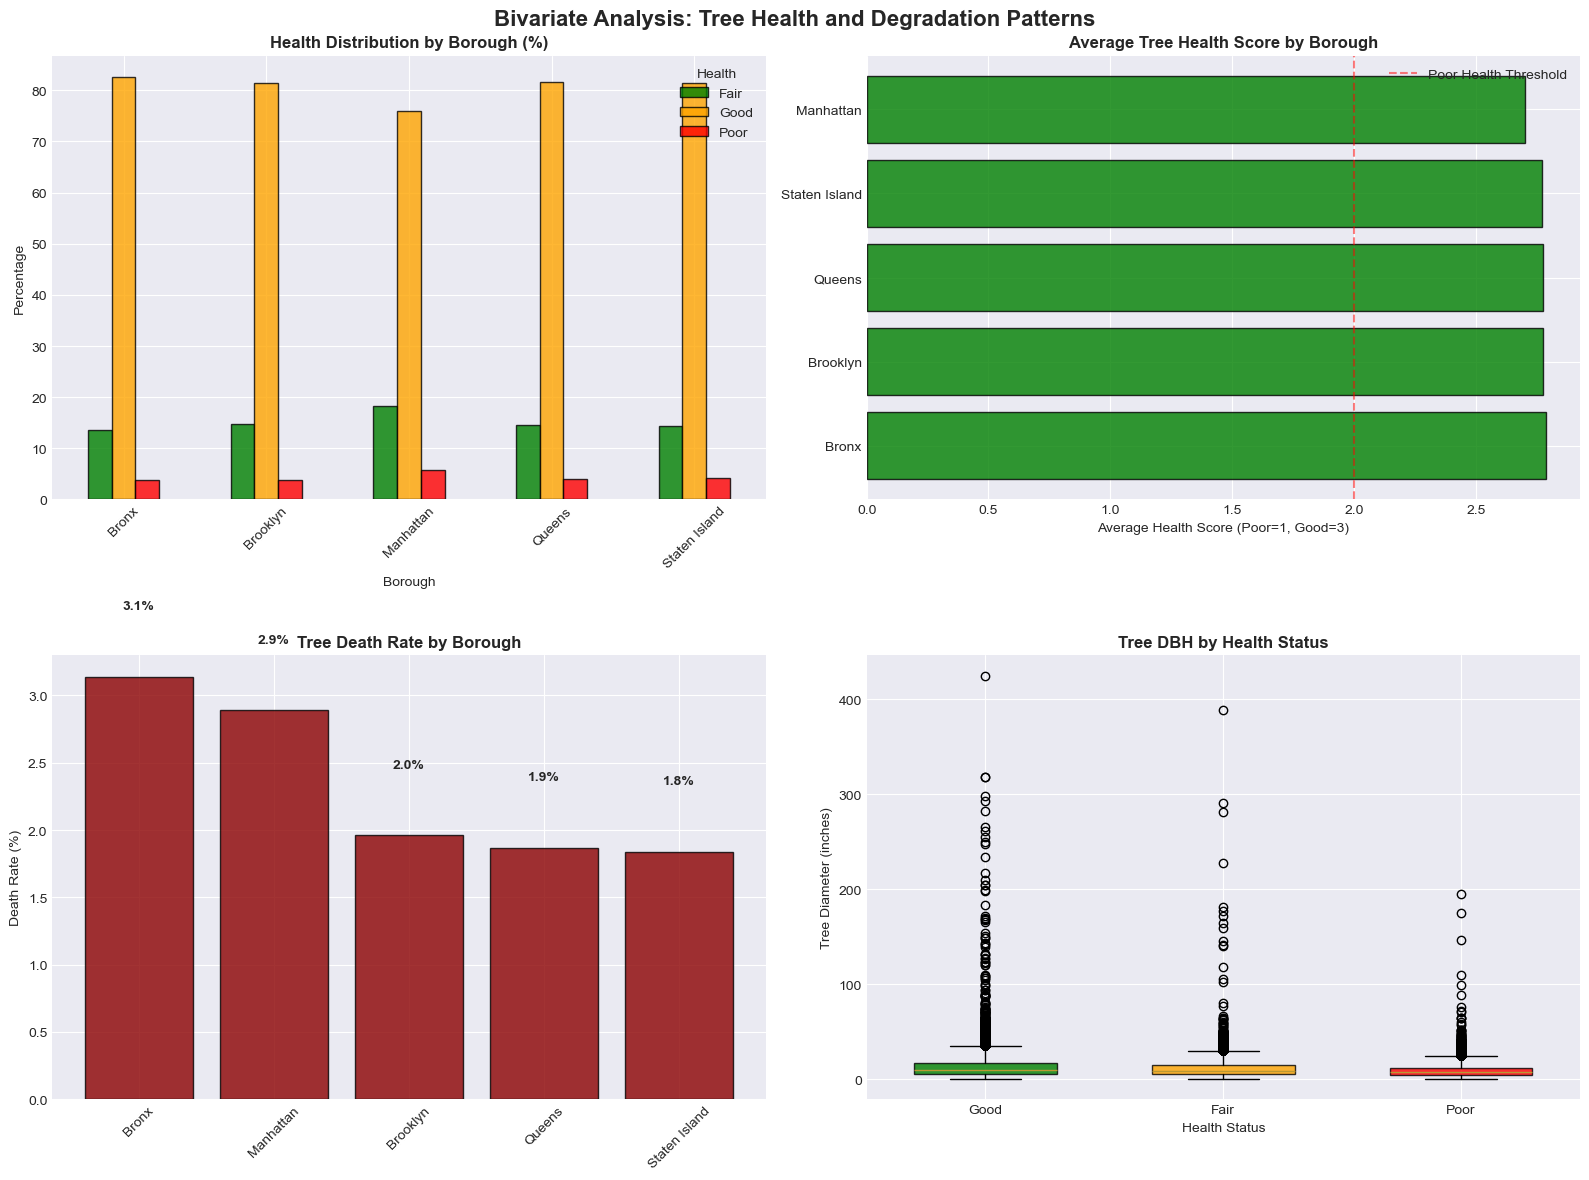

Bivariate visualization complete


In [23]:
# Bivariate visualization: Health by Borough
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Bivariate Analysis: Tree Health and Degradation Patterns', fontsize=16, fontweight='bold')

# 1. Health distribution by Borough
health_borough_pct = pd.crosstab(df['boroname'], df['health'], normalize='index') * 100
health_borough_pct.plot(kind='bar', ax=axes[0, 0], color=['green', 'orange', 'red'], alpha=0.8, edgecolor='black')
axes[0, 0].set_title('Health Distribution by Borough (%)', fontweight='bold')
axes[0, 0].set_ylabel('Percentage')
axes[0, 0].set_xlabel('Borough')
axes[0, 0].legend(title='Health', loc='upper right')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. Average Health Score by Borough
health_by_borough_sorted = health_by_borough.sort_values('Avg_Health_Score', ascending=False)
colors_boro = ['red' if x < 2.5 else 'orange' if x < 2.7 else 'green' for x in health_by_borough_sorted['Avg_Health_Score']]
axes[0, 1].barh(health_by_borough_sorted.index, health_by_borough_sorted['Avg_Health_Score'], 
                 color=colors_boro, alpha=0.8, edgecolor='black')
axes[0, 1].set_title('Average Tree Health Score by Borough', fontweight='bold')
axes[0, 1].set_xlabel('Average Health Score (Poor=1, Good=3)')
axes[0, 1].axvline(2.0, color='red', linestyle='--', alpha=0.5, label='Poor Health Threshold')
axes[0, 1].legend()

# 3. Death Rate by Borough
death_rate = health_by_borough.sort_values('Death_Rate_%', ascending=False)
axes[1, 0].bar(death_rate.index, death_rate['Death_Rate_%'], color='darkred', alpha=0.8, edgecolor='black')
axes[1, 0].set_title('Tree Death Rate by Borough', fontweight='bold')
axes[1, 0].set_ylabel('Death Rate (%)')
axes[1, 0].tick_params(axis='x', rotation=45)
for i, (boro, val) in enumerate(zip(death_rate.index, death_rate['Death_Rate_%'])):
    axes[1, 0].text(i, val + 0.5, f'{val:.1f}%', ha='center', fontweight='bold')

# 4. Tree DBH by Health Status
tree_dbh_by_health = pd.to_numeric(df['tree_dbh'], errors='coerce')
health_order_plot = ['Good', 'Fair', 'Poor']
health_dbh_data = [tree_dbh_by_health[df['health'] == h].dropna().values for h in health_order_plot if h in df['health'].values]

bp = axes[1, 1].boxplot(health_dbh_data, labels=[h for h in health_order_plot if h in df['health'].values],
                          patch_artist=True, widths=0.6)
for patch, color in zip(bp['boxes'], ['green', 'orange', 'red']):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)
axes[1, 1].set_title('Tree DBH by Health Status', fontweight='bold')
axes[1, 1].set_ylabel('Tree Diameter (inches)')
axes[1, 1].set_xlabel('Health Status')

plt.tight_layout()
plt.show()

print("Bivariate visualization complete")


BIVARIATE ANALYSIS: NUMERICAL CORRELATIONS

Pearson Correlation Matrix:
              tree_dbh  latitude  longitude  health_score
tree_dbh         1.000    -0.034      0.103         0.074
latitude        -0.034     1.000      0.576         0.008
longitude        0.103     0.576      1.000         0.015
health_score     0.074     0.008      0.015         1.000


Spearman Rank Correlation:
              tree_dbh  latitude  longitude  health_score
tree_dbh         1.000    -0.036      0.092         0.062
latitude        -0.036     1.000      0.516         0.006
longitude        0.092     0.516      1.000         0.021
health_score     0.062     0.006      0.021         1.000


CORRELATION SIGNIFICANCE TESTS:
--------------------------------------------------------------------------------

tree_dbh vs health_score:
  Pearson: r = 0.0742, p-value = 0.00e+00 (SIGNIFICANT)
  Spearman: ρ = 0.0621, p-value = 0.00e+00 (SIGNIFICANT)

latitude vs health_score:
  Pearson: r = 0.0081, p-value = 5.0

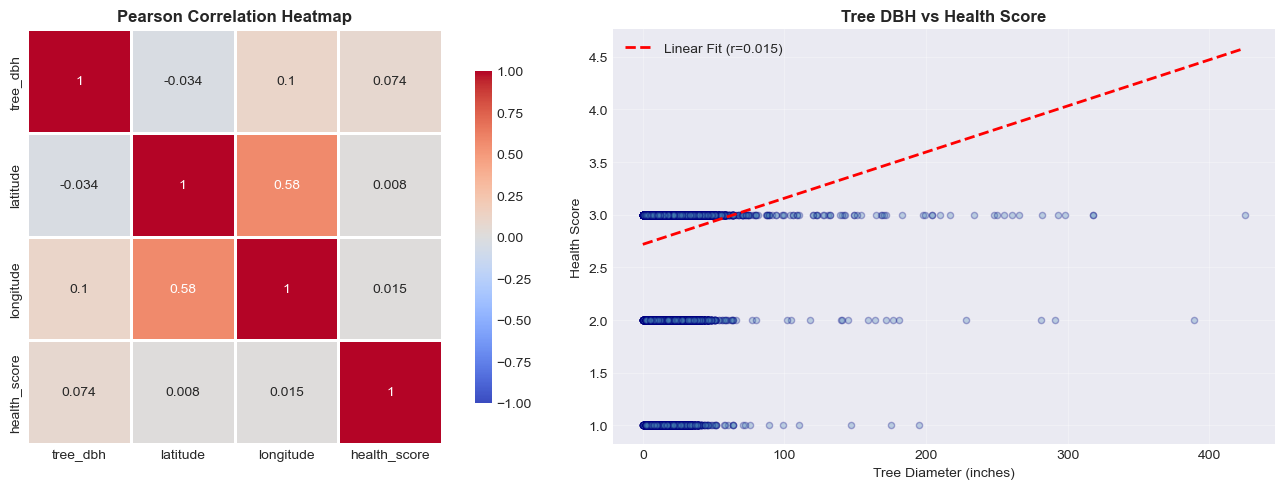

Correlation analysis complete


In [24]:
# Bivariate Analysis: Numerical Variables Correlations
print("\nBIVARIATE ANALYSIS: NUMERICAL CORRELATIONS")
print("=" * 80)

# Prepare data for correlation analysis
numeric_analysis = df[['tree_dbh', 'latitude', 'longitude', 'health_score']].copy()
numeric_analysis['tree_dbh'] = pd.to_numeric(df['tree_dbh'], errors='coerce')
numeric_analysis = numeric_analysis.dropna()

# Pearson correlation
print("\nPearson Correlation Matrix:")
pearson_corr = numeric_analysis.corr(method='pearson').round(3)
print(pearson_corr)

# Spearman correlation (rank-based, more robust to outliers)
print("\n\nSpearman Rank Correlation:")
spearman_corr = numeric_analysis.corr(method='spearman').round(3)
print(spearman_corr)

# Test significance of key correlations
print("\n\nCORRELATION SIGNIFICANCE TESTS:")
print("-" * 80)
test_pairs = [('tree_dbh', 'health_score'), ('latitude', 'health_score'), ('longitude', 'health_score')]
for var1, var2 in test_pairs:
    r_pearson, p_pearson = stats.pearsonr(numeric_analysis[var1], numeric_analysis[var2])
    r_spearman, p_spearman = spearmanr(numeric_analysis[var1], numeric_analysis[var2])
    print(f"\n{var1} vs {var2}:")
    print(f"  Pearson: r = {r_pearson:.4f}, p-value = {p_pearson:.2e} {'(SIGNIFICANT)' if p_pearson < 0.05 else ''}")
    print(f"  Spearman: ρ = {r_spearman:.4f}, p-value = {p_spearman:.2e} {'(SIGNIFICANT)' if p_spearman < 0.05 else ''}")

# Correlation visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap of correlations
sns.heatmap(pearson_corr, annot=True, cmap='coolwarm', center=0, square=True, 
            linewidths=1, cbar_kws={"shrink": 0.8}, ax=axes[0], vmin=-1, vmax=1)
axes[0].set_title('Pearson Correlation Heatmap', fontweight='bold')

# Scatter plot: Tree DBH vs Health Score
axes[1].scatter(numeric_analysis['tree_dbh'], numeric_analysis['health_score'], 
                alpha=0.3, s=20, color='steelblue', edgecolor='navy')
z = np.polyfit(numeric_analysis['tree_dbh'], numeric_analysis['health_score'], 1)
p = np.poly1d(z)
x_line = np.linspace(numeric_analysis['tree_dbh'].min(), numeric_analysis['tree_dbh'].max(), 100)
axes[1].plot(x_line, p(x_line), "r--", linewidth=2, label=f'Linear Fit (r={r_pearson:.3f})')
axes[1].set_title('Tree DBH vs Health Score', fontweight='bold')
axes[1].set_xlabel('Tree Diameter (inches)')
axes[1].set_ylabel('Health Score')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Correlation analysis complete")

## Section 5: Hypothesis Testing and Statistical Inference

In [25]:
print("HYPOTHESIS TESTING AND STATISTICAL INFERENCE")
print("=" * 80)

# Hypothesis 1: Test if tree health differs significantly across boroughs
print("\nHYPOTHESIS 1: Tree health differs significantly across boroughs")
print("-" * 80)
print("H0: Mean health scores are equal across all boroughs")
print("H1: Mean health scores differ significantly across boroughs\n")

# Prepare data for ANOVA
health_groups = [group['health_score'].dropna().values for name, group in df.groupby('boroname')]

# Perform Kruskal-Wallis test (non-parametric ANOVA)
h_stat, p_kruskal = kruskal(*health_groups)
print(f"Kruskal-Wallis Test (non-parametric):")
print(f"  H-statistic = {h_stat:.4f}, p-value = {p_kruskal:.2e}")
print(f"  Result: REJECT H0 - Significant difference" if p_kruskal < 0.05 else f"  Result: FAIL TO REJECT H0")

# Hypothesis 2: Dead vs Alive trees have different median DBH
print("\n\nHYPOTHESIS 2: Dead trees have different size (DBH) than alive trees")
print("-" * 80)
print("H0: Median DBH is equal for dead and alive trees")
print("H1: Median DBH differs between dead and alive trees\n")

alive_dbh = pd.to_numeric(df[df['status'] == 'Alive']['tree_dbh'], errors='coerce').dropna()
dead_dbh = pd.to_numeric(df[df['status'] == 'Dead']['tree_dbh'], errors='coerce').dropna()

print(f"Alive trees - n={len(alive_dbh)}, median DBH={alive_dbh.median():.2f}, mean={alive_dbh.mean():.2f}")
print(f"Dead trees - n={len(dead_dbh)}, median DBH={dead_dbh.median():.2f}, mean={dead_dbh.mean():.2f}\n")

# Mann-Whitney U test (non-parametric t-test)
u_stat, p_mann = stats.mannwhitneyu(alive_dbh, dead_dbh)
print(f"Mann-Whitney U Test (non-parametric):")
print(f"  U-statistic = {u_stat:.4f}, p-value = {p_mann:.2e}")
print(f"  Result: REJECT H0 - Significant difference" if p_mann < 0.05 else f"  Result: FAIL TO REJECT H0")

# Hypothesis 3: Test association between stewardship and health
print("\n\nHYPOTHESIS 3: Stewardship level is associated with tree health")
print("-" * 80)
print("H0: Tree health is independent of stewardship level")
print("H1: Tree health depends on stewardship level\n")

steward_types = df['steward'].value_counts().head(4).index
steward_health = df[df['steward'].isin(steward_types)].copy()

steward_health_tab = pd.crosstab(steward_health['steward'], steward_health['health'])
chi2_steward, p_steward, dof_s, exp_s = chi2_contingency(steward_health_tab)
print(f"Chi-Square Test:")
print(f"  x² = {chi2_steward:.4f}, p-value = {p_steward:.2e}, df = {dof_s}")
print(f"  Result: REJECT H0 - Significant association" if p_steward < 0.05 else f"  Result: FAIL TO REJECT H0")

print("\nStewardship vs Health Distribution:")
print(pd.crosstab(steward_health['steward'], steward_health['health'], normalize='index').round(3) * 100)

# 95% Confidence Interval for proportion of poor health trees
poor_health_count = (df['health'] == 'Poor').sum()
total_count = df['health'].notna().sum()
poor_prop = poor_health_count / total_count

se = np.sqrt(poor_prop * (1 - poor_prop) / total_count)
ci_lower = poor_prop - 1.96 * se
ci_upper = poor_prop + 1.96 * se

print(f"\n\nCONFIDENCE INTERVAL ESTIMATION")
print("-" * 80)
print(f"95% CI for proportion of trees in poor health:")
print(f"  Point estimate: {poor_prop:.4f} ({poor_prop*100:.2f}%)")
print(f"  95% CI: [{ci_lower:.4f}, {ci_upper:.4f}] or [{ci_lower*100:.2f}%, {ci_upper*100:.2f}%]")

HYPOTHESIS TESTING AND STATISTICAL INFERENCE

HYPOTHESIS 1: Tree health differs significantly across boroughs
--------------------------------------------------------------------------------
H0: Mean health scores are equal across all boroughs
H1: Mean health scores differ significantly across boroughs

Kruskal-Wallis Test (non-parametric):
  H-statistic = 1328.0075, p-value = 2.82e-286
  Result: REJECT H0 - Significant difference


HYPOTHESIS 2: Dead trees have different size (DBH) than alive trees
--------------------------------------------------------------------------------
H0: Median DBH is equal for dead and alive trees
H1: Median DBH differs between dead and alive trees

Alive trees - n=652173, median DBH=10.00, mean=11.71
Dead trees - n=13961, median DBH=4.00, mean=5.47

Mann-Whitney U Test (non-parametric):
  U-statistic = 6960276646.5000, p-value = 0.00e+00
  Result: REJECT H0 - Significant difference


HYPOTHESIS 3: Stewardship level is associated with tree health
---------

## Section 6: Regression Analysis

LINEAR AND NON-LINEAR REGRESSION ANALYSIS

1. SIMPLE LINEAR REGRESSION: Tree DBH → Health Score
--------------------------------------------------------------------------------

Model Coefficients:
  Intercept: 2.7185
  Tree DBH coefficient: 0.004380

Model Performance:
  R² Score: 0.0055
  RMSE: 0.5080
  MAE: 0.3716

Interpretation: Each additional inch of tree diameter is associated with a 0.0044 change in health score


2. MULTIPLE LINEAR REGRESSION: Tree DBH + Borough + Location → Health Score
--------------------------------------------------------------------------------

Model Coefficients:
  Intercept: 1.6894
  Tree DBH: 0.004391
  Borough (encoded): -0.001451
  Latitude: 0.042622
  Longitude: 0.009505

Model Performance:
  R² Score: 0.0056
  RMSE: 0.5079
  MAE: 0.3715


MODEL COMPARISON:
Metric               Simple LR       Multiple LR     Improvement    
-----------------------------------------------------------------
R² Score             0.0055          0.0056          +0.0

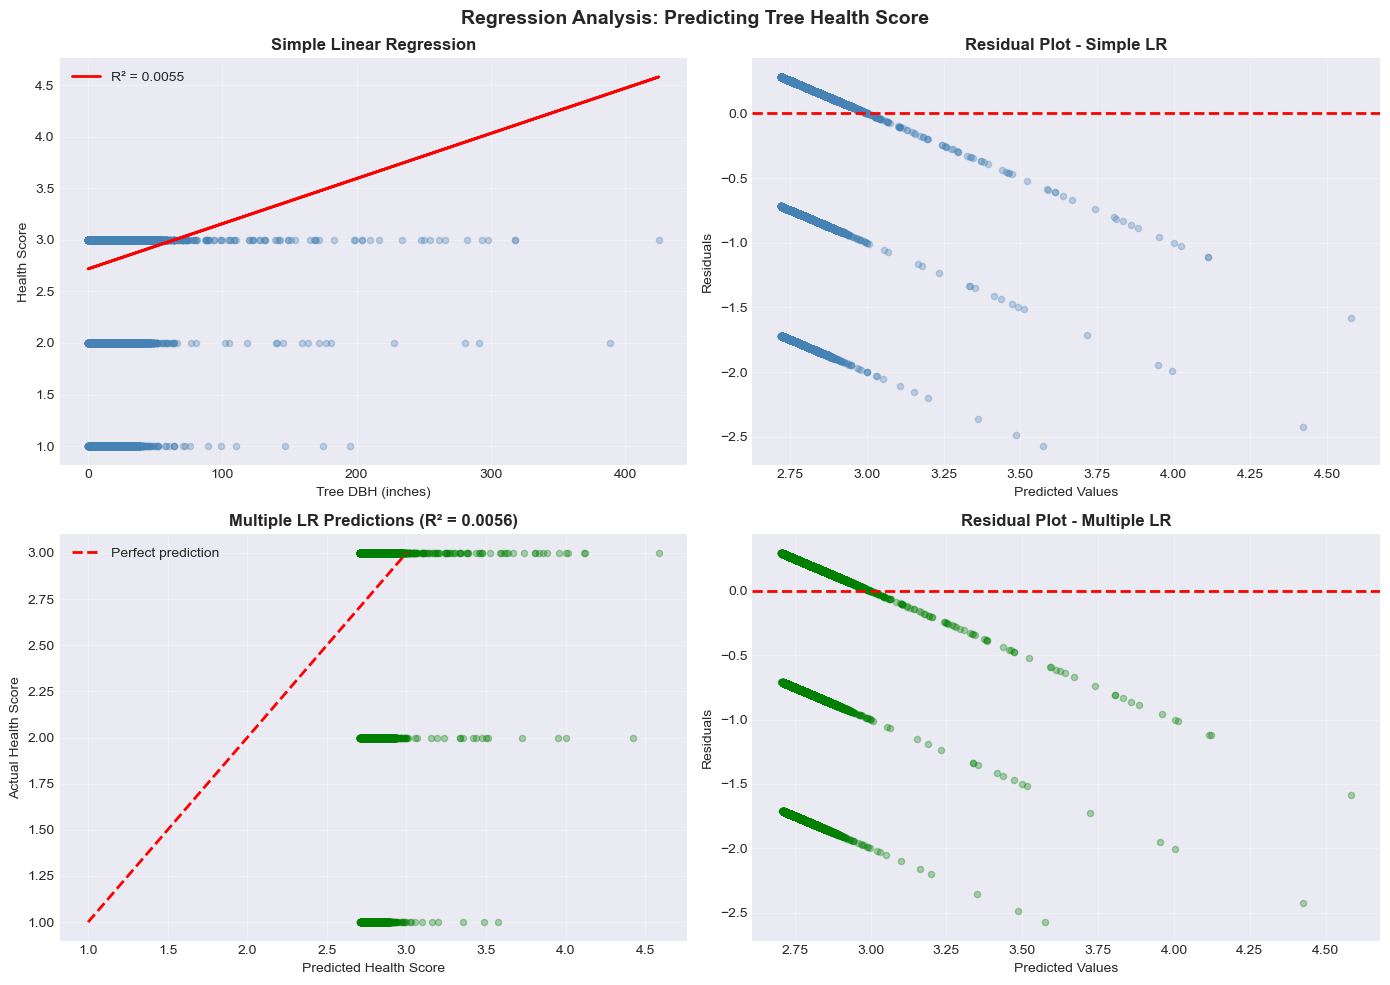

Regression analysis complete


In [26]:
print("LINEAR AND NON-LINEAR REGRESSION ANALYSIS")
print("=" * 80)

# Prepare regression data
regression_data = df[['tree_dbh', 'health_score', 'boroname', 'latitude', 'longitude']].copy()
regression_data['tree_dbh'] = pd.to_numeric(df['tree_dbh'], errors='coerce')
regression_data = regression_data.dropna()

# Encode borough names
le_boro = LabelEncoder()
regression_data['boroname_encoded'] = le_boro.fit_transform(regression_data['boroname'])

# Simple Linear Regression: Predicting Health Score from Tree DBH
print("\n1. SIMPLE LINEAR REGRESSION: Tree DBH → Health Score")
print("-" * 80)

# Prepare features and target variable
X_simple = regression_data[['tree_dbh']].values
y = regression_data['health_score'].values

# Train simple linear regression model
lr_simple = LinearRegression()
lr_simple.fit(X_simple, y)
y_pred_simple = lr_simple.predict(X_simple)

# Evaluate simple linear regression model
r2_simple = r2_score(y, y_pred_simple)
rmse_simple = np.sqrt(mean_squared_error(y, y_pred_simple))
mae_simple = mean_absolute_error(y, y_pred_simple)

print(f"\nModel Coefficients:")
print(f"  Intercept: {lr_simple.intercept_:.4f}")
print(f"  Tree DBH coefficient: {lr_simple.coef_[0]:.6f}")
print(f"\nModel Performance:")
print(f"  R² Score: {r2_simple:.4f}")
print(f"  RMSE: {rmse_simple:.4f}")
print(f"  MAE: {mae_simple:.4f}")
print(f"\nInterpretation: Each additional inch of tree diameter is associated with a {lr_simple.coef_[0]:.4f} change in health score")

# Multiple Linear Regression
print("\n\n2. MULTIPLE LINEAR REGRESSION: Tree DBH + Borough + Location → Health Score")
print("-" * 80)

# Prepare features and target variable
X_multi = regression_data[['tree_dbh', 'boroname_encoded', 'latitude', 'longitude']].values
lr_multi = LinearRegression()
lr_multi.fit(X_multi, y)
y_pred_multi = lr_multi.predict(X_multi)

# Evaluate multiple linear regression model
r2_multi = r2_score(y, y_pred_multi)
rmse_multi = np.sqrt(mean_squared_error(y, y_pred_multi))
mae_multi = mean_absolute_error(y, y_pred_multi)

print(f"\nModel Coefficients:")
print(f"  Intercept: {lr_multi.intercept_:.4f}")
print(f"  Tree DBH: {lr_multi.coef_[0]:.6f}")
print(f"  Borough (encoded): {lr_multi.coef_[1]:.6f}")
print(f"  Latitude: {lr_multi.coef_[2]:.6f}")
print(f"  Longitude: {lr_multi.coef_[3]:.6f}")
print(f"\nModel Performance:")
print(f"  R² Score: {r2_multi:.4f}")
print(f"  RMSE: {rmse_multi:.4f}")
print(f"  MAE: {mae_multi:.4f}")

# Comparison
print(f"\n\nMODEL COMPARISON:")
print(f"{'Metric':<20} {'Simple LR':<15} {'Multiple LR':<15} {'Improvement':<15}")
print("-" * 65)
print(f"{'R² Score':<20} {r2_simple:<15.4f} {r2_multi:<15.4f} {'+' if r2_multi > r2_simple else ''}{(r2_multi - r2_simple):.4f}")
print(f"{'RMSE':<20} {rmse_simple:<15.4f} {rmse_multi:<15.4f} {'-' if rmse_multi < rmse_simple else ''}{abs(rmse_simple - rmse_multi):.4f}")

# Random Forest Regression (Non-linear)
print("\n\n3. RANDOM FOREST REGRESSION (Non-linear)")
print("-" * 80)

# Train a Random Forest Regressor
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=15)
rf_reg.fit(X_multi, y)
y_pred_rf = rf_reg.predict(X_multi)

# Evaluate Random Forest model
r2_rf = r2_score(y, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y, y_pred_rf))
mae_rf = mean_absolute_error(y, y_pred_rf)

print(f"\nModel Performance:")
print(f"  R² Score: {r2_rf:.4f}")
print(f"  RMSE: {rmse_rf:.4f}")
print(f"  MAE: {mae_rf:.4f}")

# Feature importance
feature_names = ['tree_dbh', 'boroname_encoded', 'latitude', 'longitude']
feature_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': rf_reg.feature_importances_
}).sort_values('importance', ascending=False)

print(f"\nFeature Importance:")
print(feature_importance.to_string(index=False))

# Visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Regression Analysis: Predicting Tree Health Score', fontsize=14, fontweight='bold')

# Simple Linear Regression
axes[0, 0].scatter(X_simple, y, alpha=0.3, s=20, color='steelblue')
axes[0, 0].plot(X_simple, y_pred_simple, 'r-', linewidth=2, label=f'R² = {r2_simple:.4f}')
axes[0, 0].set_xlabel('Tree DBH (inches)')
axes[0, 0].set_ylabel('Health Score')
axes[0, 0].set_title('Simple Linear Regression', fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Residuals - Simple
residuals_simple = y - y_pred_simple
axes[0, 1].scatter(y_pred_simple, residuals_simple, alpha=0.3, s=20, color='steelblue')
axes[0, 1].axhline(y=0, color='r', linestyle='--', linewidth=2)
axes[0, 1].set_xlabel('Predicted Values')
axes[0, 1].set_ylabel('Residuals')
axes[0, 1].set_title('Residual Plot - Simple LR', fontweight='bold')
axes[0, 1].grid(alpha=0.3)

# Multiple Linear Regression
axes[1, 0].scatter(y_pred_multi, y, alpha=0.3, s=20, color='green')
axes[1, 0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', linewidth=2, label='Perfect prediction')
axes[1, 0].set_xlabel('Predicted Health Score')
axes[1, 0].set_ylabel('Actual Health Score')
axes[1, 0].set_title(f'Multiple LR Predictions (R² = {r2_multi:.4f})', fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Residuals - Multiple
residuals_multi = y - y_pred_multi
axes[1, 1].scatter(y_pred_multi, residuals_multi, alpha=0.3, s=20, color='green')
axes[1, 1].axhline(y=0, color='r', linestyle='--', linewidth=2)
axes[1, 1].set_xlabel('Predicted Values')
axes[1, 1].set_ylabel('Residuals')
axes[1, 1].set_title('Residual Plot - Multiple LR', fontweight='bold')
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Regression analysis complete")

## Section 7: Classification Analysis

In [27]:
print("CLASSIFICATION ANALYSIS: PREDICTING TREE HEALTH STATUS")
print("=" * 80)

# Prepare classification data
class_data = df[['tree_dbh', 'boroname', 'latitude', 'longitude', 'status', 'health', 'steward', 'guards']].copy()
class_data['tree_dbh'] = pd.to_numeric(class_data['tree_dbh'], errors='coerce')
class_data = class_data.dropna()

# Target: Predict if tree is in Poor health (1) or Not Poor (0)
class_data['poor_health'] = (class_data['health'] == 'Poor').astype(int)

# Encode categorical variables
le_boro_class = LabelEncoder()
le_steward = LabelEncoder()
le_guards = LabelEncoder()

# Encode borough, steward, and guards for classification models
class_data['boro_encoded'] = le_boro_class.fit_transform(class_data['boroname'])
class_data['steward_encoded'] = le_steward.fit_transform(class_data['steward'])
class_data['guards_encoded'] = le_guards.fit_transform(class_data['guards'])

# Prepare features and target
X_class = class_data[['tree_dbh', 'boro_encoded', 'latitude', 'longitude', 'steward_encoded', 'guards_encoded']].values
y_class = class_data['poor_health'].values

# Standardize features for logistic regression
scaler = StandardScaler()
X_class_scaled = scaler.fit_transform(X_class)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X_class_scaled, y_class, test_size=0.25, random_state=42, stratify=y_class)

print(f"\nData Split:")
print(f"  Training set: {len(X_train)} samples")
print(f"  Test set: {len(X_test)} samples")
print(f"  Class distribution (Poor health): {sum(y_train)/len(y_train)*100:.2f}% (train), {sum(y_test)/len(y_test)*100:.2f}% (test)")

# 1. Logistic Regression
print("\n\n1. LOGISTIC REGRESSION")
print("-" * 80)

# Train logistic regression model
lr_class = LogisticRegression(random_state=42, max_iter=1000)
lr_class.fit(X_train, y_train)
y_pred_lr = lr_class.predict(X_test)
y_pred_proba_lr = lr_class.predict_proba(X_test)[:, 1]

print(f"\nModel Performance (Test Set):")
print(f"  Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"  Precision: {precision_score(y_test, y_pred_lr):.4f}")
print(f"  Recall: {recall_score(y_test, y_pred_lr):.4f}")
print(f"  F1-Score: {f1_score(y_test, y_pred_lr):.4f}")

print(f"\nClassification Report:")
print(classification_report(y_test, y_pred_lr, target_names=['Not Poor Health', 'Poor Health']))

# 2. Random Forest Classification
print("\n\n2. RANDOM FOREST CLASSIFICATION")
print("-" * 80)

# Train Random Forest Classifier
rf_class = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=15)
rf_class.fit(X_train, y_train)
y_pred_rf_class = rf_class.predict(X_test)
y_pred_proba_rf = rf_class.predict_proba(X_test)[:, 1]

print(f"\nModel Performance (Test Set):")
print(f"  Accuracy: {accuracy_score(y_test, y_pred_rf_class):.4f}")
print(f"  Precision: {precision_score(y_test, y_pred_rf_class):.4f}")
print(f"  Recall: {recall_score(y_test, y_pred_rf_class):.4f}")
print(f"  F1-Score: {f1_score(y_test, y_pred_rf_class):.4f}")

print(f"\nClassification Report:")
print(classification_report(y_test, y_pred_rf_class, target_names=['Not Poor Health', 'Poor Health']))

# 3. Gradient Boosting Classification
print("\n\n3. GRADIENT BOOSTING CLASSIFICATION")
print("-" * 80)

# Train Gradient Boosting Classifier
gbc = GradientBoostingClassifier(n_estimators=100, random_state=42, max_depth=5)
gbc.fit(X_train, y_train)
y_pred_gbc = gbc.predict(X_test)
y_pred_proba_gbc = gbc.predict_proba(X_test)[:, 1]

print(f"\nModel Performance (Test Set):")
print(f"  Accuracy: {accuracy_score(y_test, y_pred_gbc):.4f}")
print(f"  Precision: {precision_score(y_test, y_pred_gbc):.4f}")
print(f"  Recall: {recall_score(y_test, y_pred_gbc):.4f}")
print(f"  F1-Score: {f1_score(y_test, y_pred_gbc):.4f}")

print(f"\nClassification Report:")
print(classification_report(y_test, y_pred_gbc, target_names=['Not Poor Health', 'Poor Health']))

# Model Comparison
print("\n\nMODEL COMPARISON:")
print("-" * 80)
models_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'Gradient Boosting'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf_class),
        accuracy_score(y_test, y_pred_gbc)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf_class),
        precision_score(y_test, y_pred_gbc)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf_class),
        recall_score(y_test, y_pred_gbc)
    ],
    'F1-Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf_class),
        f1_score(y_test, y_pred_gbc)
    ]
})
print(models_comparison.round(4).to_string(index=False))

# Identify best model based on F1-Score
best_model_idx = models_comparison['F1-Score'].idxmax()
print(f"\nBest Model: {models_comparison.iloc[best_model_idx]['Model']}")

# Feature importance from Random Forest
print("\n\nFEATURE IMPORTANCE (Random Forest Classification):")
print("-" * 80)
feature_names_class = ['tree_dbh', 'borough', 'latitude', 'longitude', 'stewardship', 'guards']
feature_imp_class = pd.DataFrame({
    'feature': feature_names_class,
    'importance': rf_class.feature_importances_
}).sort_values('importance', ascending=False)
print(feature_imp_class.to_string(index=False))

CLASSIFICATION ANALYSIS: PREDICTING TREE HEALTH STATUS

Data Split:
  Training set: 49954 samples
  Test set: 16652 samples
  Class distribution (Poor health): 4.53% (train), 4.53% (test)


1. LOGISTIC REGRESSION
--------------------------------------------------------------------------------

Model Performance (Test Set):
  Accuracy: 0.9547
  Precision: 0.0000
  Recall: 0.0000
  F1-Score: 0.0000

Classification Report:
                 precision    recall  f1-score   support

Not Poor Health       0.95      1.00      0.98     15898
    Poor Health       0.00      0.00      0.00       754

       accuracy                           0.95     16652
      macro avg       0.48      0.50      0.49     16652
   weighted avg       0.91      0.95      0.93     16652



2. RANDOM FOREST CLASSIFICATION
--------------------------------------------------------------------------------

Model Performance (Test Set):
  Accuracy: 0.9550
  Precision: 0.7000
  Recall: 0.0093
  F1-Score: 0.0183

Classific

**NOTE: Why Random Forest Classification?** Random Forest doesn't assume linear relationships between features (unlike Logistic Regression), so it captures how stewardship effectiveness varies by borough, how tree size impacts health differently in different neighborhoods, and complex interactions between location, diameter, and maintenance type. Additionally, my dataset mixes continuous and categorical variables, which Random Forest handles naturally without requiring scaling like Logistic Regression does.

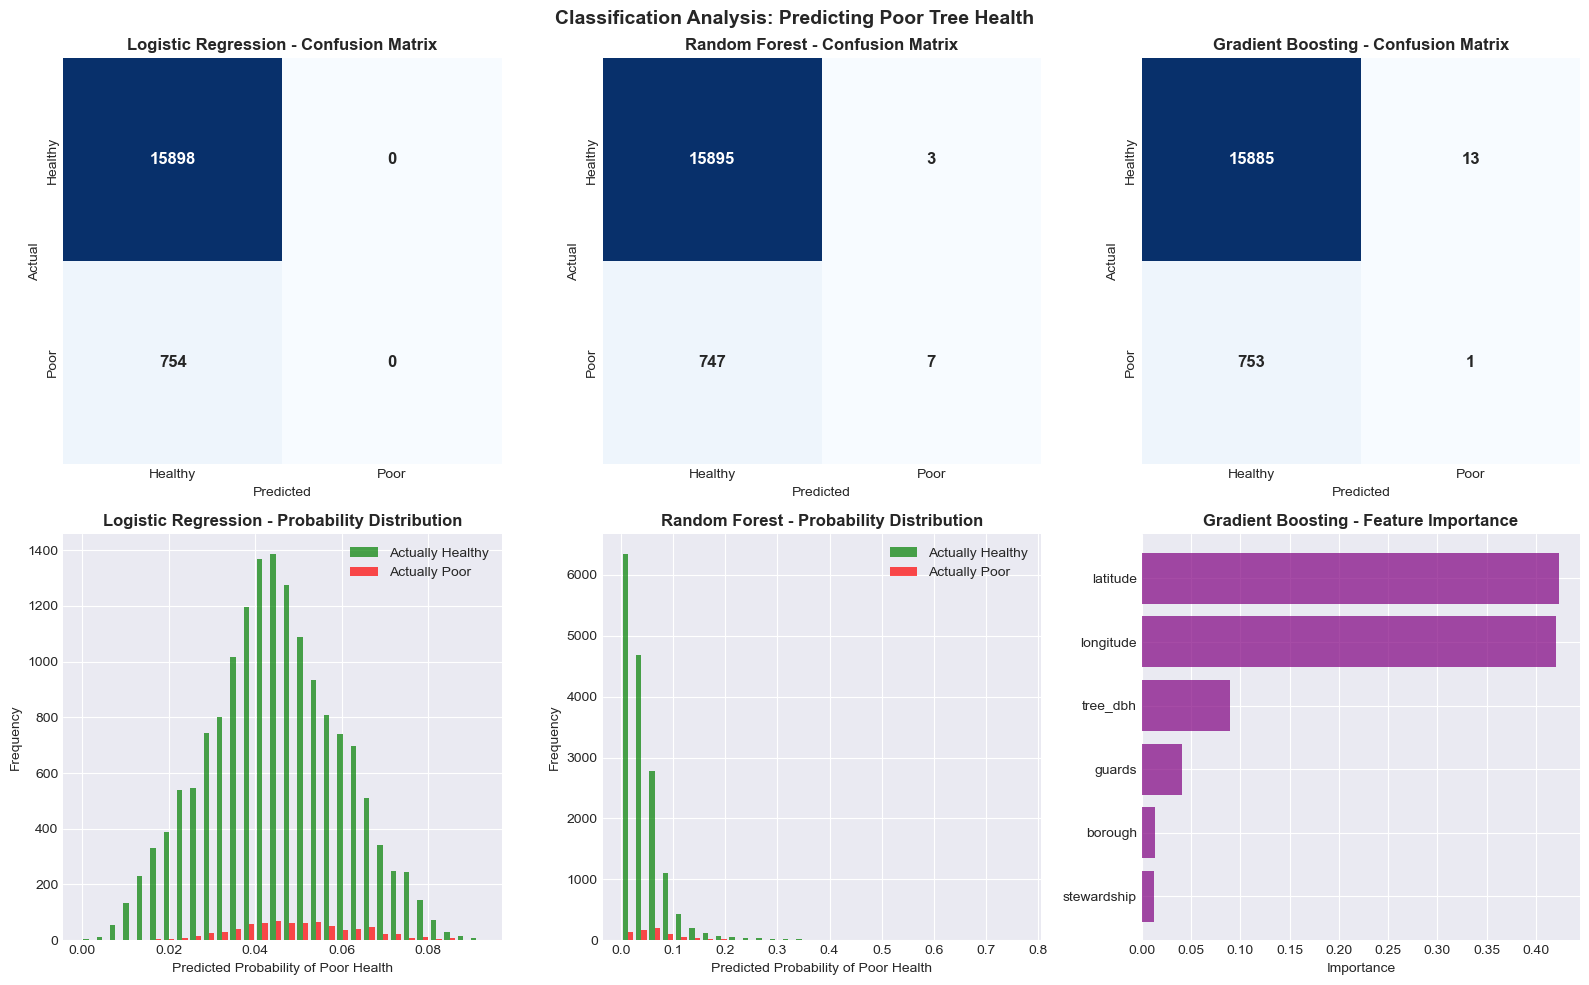

Classification analysis complete


In [28]:
# Classification Visualization
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Classification Analysis: Predicting Poor Tree Health', fontsize=14, fontweight='bold')

# Confusion Matrices
from sklearn.metrics import confusion_matrix as cm

# Define model info for plotting
models_info = [
    ('Logistic Regression', y_pred_lr, 0),
    ('Random Forest', y_pred_rf_class, 1),
    ('Gradient Boosting', y_pred_gbc, 2)
]

# Plot confusion matrices for each model
for model_name, y_pred, col_idx in models_info:
    cm_matrix = cm(y_test, y_pred)
    sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='Blues', ax=axes[0, col_idx], 
                xticklabels=['Healthy', 'Poor'], yticklabels=['Healthy', 'Poor'],
                cbar=False, annot_kws={'size': 12, 'weight': 'bold'})
    axes[0, col_idx].set_title(f'{model_name} - Confusion Matrix', fontweight='bold')
    axes[0, col_idx].set_ylabel('Actual')
    axes[0, col_idx].set_xlabel('Predicted')

# ROC-like comparison: Prediction probabilities
axes[1, 0].hist([y_pred_proba_lr[y_test == 0], y_pred_proba_lr[y_test == 1]], 
                bins=30, label=['Actually Healthy', 'Actually Poor'], alpha=0.7, color=['green', 'red'])
axes[1, 0].set_title('Logistic Regression - Probability Distribution', fontweight='bold')
axes[1, 0].set_xlabel('Predicted Probability of Poor Health')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].legend()

axes[1, 1].hist([y_pred_proba_rf[y_test == 0], y_pred_proba_rf[y_test == 1]], 
                bins=30, label=['Actually Healthy', 'Actually Poor'], alpha=0.7, color=['green', 'red'])
axes[1, 1].set_title('Random Forest - Probability Distribution', fontweight='bold')
axes[1, 1].set_xlabel('Predicted Probability of Poor Health')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].legend()

# Feature importance comparison
feature_imp_gb = pd.DataFrame({
    'feature': feature_names_class,
    'importance': gbc.feature_importances_
}).sort_values('importance', ascending=False)

axes[1, 2].barh(feature_imp_gb['feature'], feature_imp_gb['importance'], color='purple', alpha=0.7)
axes[1, 2].set_title('Gradient Boosting - Feature Importance', fontweight='bold')
axes[1, 2].set_xlabel('Importance')
axes[1, 2].invert_yaxis()

plt.tight_layout()
plt.show()

print("Classification analysis complete")

## Section 8: Clustering Analysis

In [29]:
print("CLUSTERING ANALYSIS: IDENTIFYING TREE SECTORS BY HEALTH CHARACTERISTICS")
print("=" * 80)

# Prepare clustering data
cluster_data = df[['tree_dbh', 'boroname', 'latitude', 'longitude', 'health_score']].copy()
cluster_data['tree_dbh'] = pd.to_numeric(cluster_data['tree_dbh'], errors='coerce')

# Encode borough names for clustering
le_cluster = LabelEncoder()
cluster_data['boro_encoded'] = le_cluster.fit_transform(cluster_data['boroname'])
cluster_data = cluster_data.dropna()

# Sample data for faster clustering (using 50,000 samples instead of full dataset)
sample_size = min(50000, len(cluster_data))
cluster_data_sample = cluster_data.sample(n=sample_size, random_state=42)
print(f"\nUsing {sample_size:,} samples from {len(cluster_data):,} total trees for clustering analysis")

# Prepare features
X_cluster = cluster_data_sample[['tree_dbh', 'boro_encoded', 'latitude', 'longitude', 'health_score']].values
X_cluster_scaled = StandardScaler().fit_transform(X_cluster)

# Determine optimal number of clusters using elbow method
print("\nDetermining optimal number of clusters...")
inertias = []
K_range = range(2, 8)  # Reduced range for faster computation

# Compute K-Means for each k and store inertia
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=5)
    kmeans.fit(X_cluster_scaled)
    inertias.append(kmeans.inertia_)

# Find optimal k using elbow heuristic
optimal_k_inertia = K_range[np.argmin(np.gradient(np.gradient(inertias)))]
optimal_k = max(2, min(optimal_k_inertia, 5))  # Use default of 3-5 clusters

print(f"Optimal K (Elbow Method): {optimal_k}")

# Apply K-Means with optimal k
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(X_cluster_scaled)
cluster_data_sample['cluster'] = cluster_labels

# Cluster Analysis
print("\n\n1. K-MEANS CLUSTERING RESULTS")
print("-" * 80)

cluster_summary = cluster_data_sample.groupby('cluster').agg({
    'tree_dbh': ['count', 'mean', 'std'],
    'latitude': 'mean',
    'longitude': 'mean',
    'health_score': 'mean',
    'boroname': lambda x: x.mode()[0] if len(x.mode()) > 0 else 'Unknown'
}).round(3)

print("\nCluster Characteristics:")
for i in range(optimal_k):
    cluster_subset = cluster_data_sample[cluster_data_sample['cluster'] == i]
    print(f"\nCluster {i} ({len(cluster_subset)} trees):")
    print(f"  - Average Tree DBH: {cluster_subset['tree_dbh'].mean():.2f} inches")
    print(f"  - Average Health Score: {cluster_subset['health_score'].mean():.2f}")
    print(f"  - Primary Borough: {cluster_subset['boroname'].mode()[0]}")
    print(f"  - Geographic Center: Lat {cluster_subset['latitude'].mean():.4f}, Lon {cluster_subset['longitude'].mean():.4f}")
    print(f"  - % Poor Health: {(cluster_subset['health_score'] < 2).mean() * 100:.2f}%")

# DBSCAN Clustering
print("\n\n2. DBSCAN CLUSTERING")
print("-" * 80)

dbscan = DBSCAN(eps=0.5, min_samples=20)
dbscan_labels = dbscan.fit_predict(X_cluster_scaled)

n_clusters_dbscan = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_outliers = list(dbscan_labels).count(-1)

print(f"Number of clusters found: {n_clusters_dbscan}")
print(f"Number of noise points (outliers): {n_outliers}")

# Add DBSCAN labels to data
cluster_data_sample['dbscan_cluster'] = dbscan_labels

# Summarize DBSCAN results
for cluster_id in sorted(set(dbscan_labels)):
    if cluster_id == -1:
        cluster_subset = cluster_data_sample[cluster_data_sample['dbscan_cluster'] == cluster_id]
        print(f"\nOutliers ({len(cluster_subset)} points):")
        print(f"  - Average Health Score: {cluster_subset['health_score'].mean():.2f}")
    else:
        cluster_subset = cluster_data_sample[cluster_data_sample['dbscan_cluster'] == cluster_id]
        print(f"\nDBSCAN Cluster {cluster_id} ({len(cluster_subset)} points):")
        print(f"  - Average Health Score: {cluster_subset['health_score'].mean():.2f}")

# Dimensionality Reduction for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_cluster_scaled)

print(f"\n\nPCA VARIANCE EXPLAINED:")
print(f"  PC1: {pca.explained_variance_ratio_[0]*100:.2f}%")
print(f"  PC2: {pca.explained_variance_ratio_[1]*100:.2f}%")
print(f"  Total: {sum(pca.explained_variance_ratio_)*100:.2f}%")

CLUSTERING ANALYSIS: IDENTIFYING TREE SECTORS BY HEALTH CHARACTERISTICS

Using 50,000 samples from 652,172 total trees for clustering analysis

Determining optimal number of clusters...
Optimal K (Elbow Method): 5


1. K-MEANS CLUSTERING RESULTS
--------------------------------------------------------------------------------

Cluster Characteristics:

Cluster 0 (12915 trees):
  - Average Tree DBH: 11.93 inches
  - Average Health Score: 3.00
  - Primary Borough: Brooklyn
  - Geographic Center: Lat 40.6678, Lon -73.9581
  - % Poor Health: 0.00%

Cluster 1 (14933 trees):
  - Average Tree DBH: 13.41 inches
  - Average Health Score: 3.00
  - Primary Borough: Queens
  - Geographic Center: Lat 40.7221, Lon -73.8146
  - % Poor Health: 0.00%

Cluster 2 (7199 trees):
  - Average Tree DBH: 9.65 inches
  - Average Health Score: 2.88
  - Primary Borough: Bronx
  - Geographic Center: Lat 40.8436, Lon -73.8883
  - % Poor Health: 0.00%

Cluster 3 (7504 trees):
  - Average Tree DBH: 10.71 inches
  - Av

**Note: Why DBSCAN clustering?** Unlike K-Means, which assigns every point to a cluster, DBSCAN marks unusual trees as noise points (labeled -1). This is critical for the analysis because it helps identify geographic areas with unusual health patterns that deviate from broader sector trends. DBSCAN also discovers clusters based on density, revealing how trees naturally cluster by health characteristics without forcing an artificial structure. Since my data isn't uniformly distributed, DBSCAN is better than K-Means since it respects local density variations.

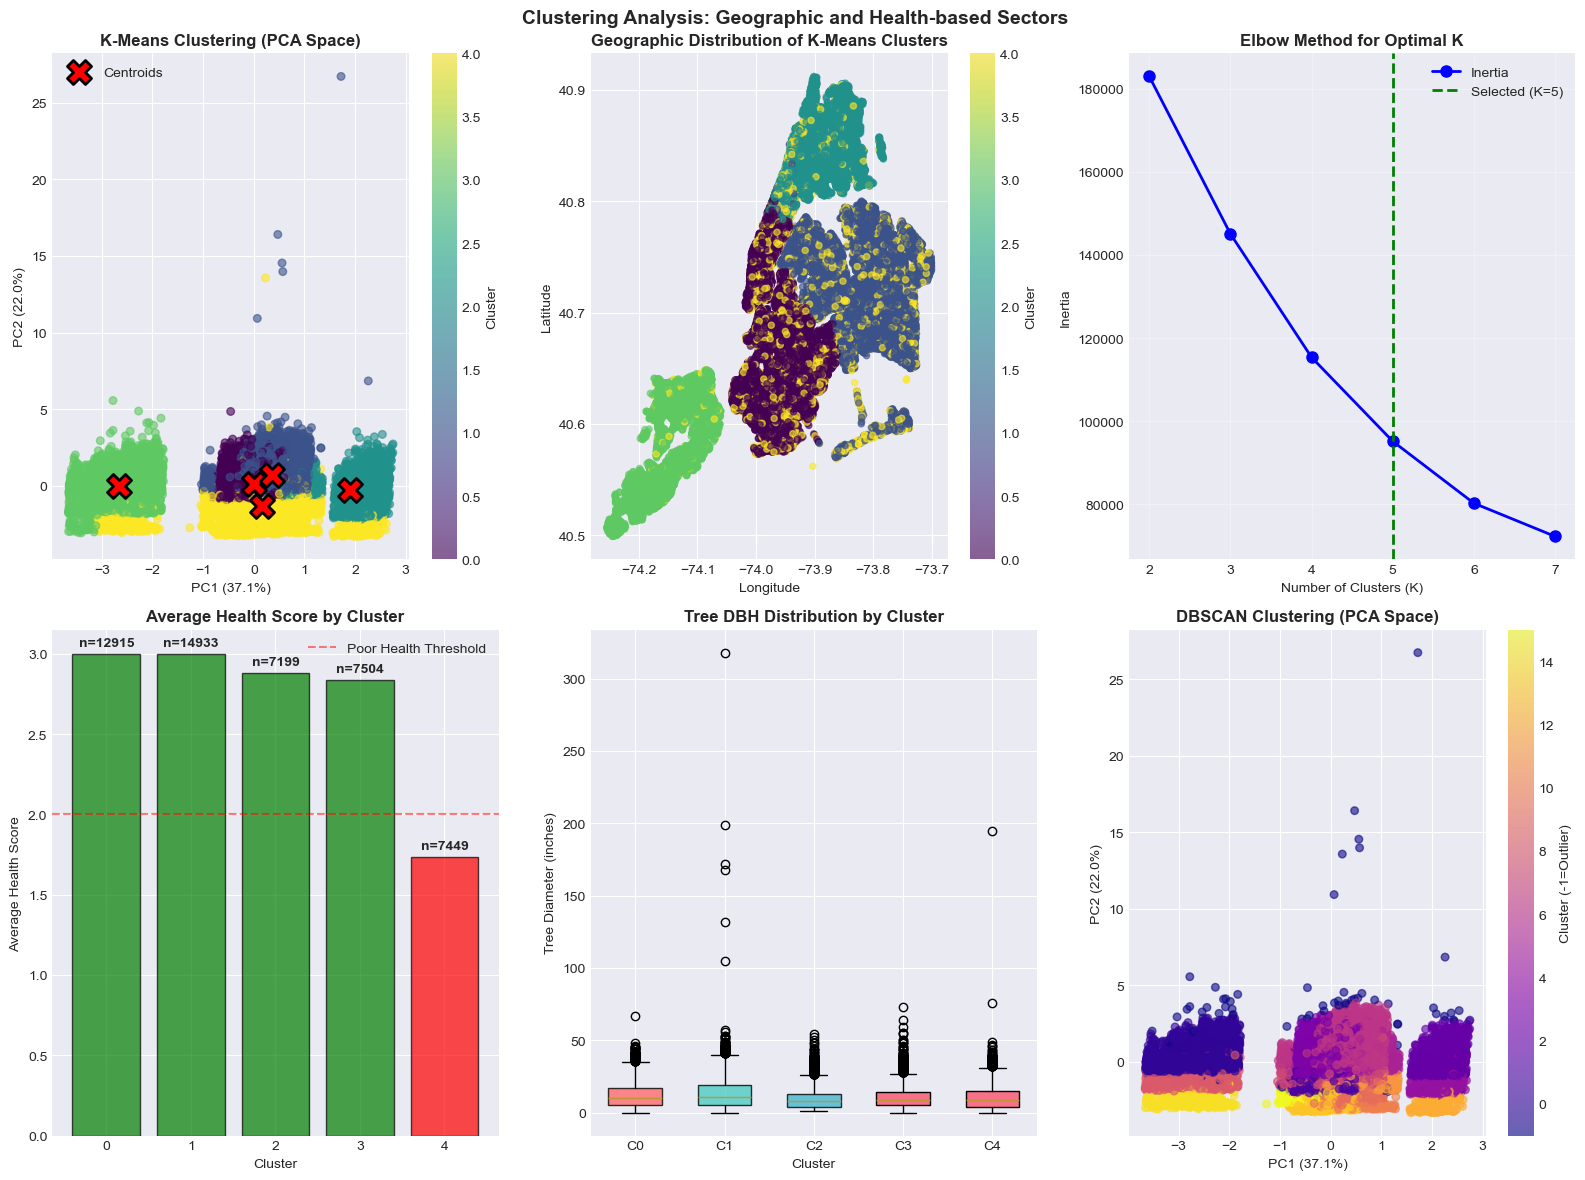

Clustering analysis complete


In [30]:
# Clustering Visualization
fig, axes = plt.subplots(2, 3, figsize=(16, 12))
fig.suptitle('Clustering Analysis: Geographic and Health-based Sectors', fontsize=14, fontweight='bold')

# K-Means in PCA space
scatter1 = axes[0, 0].scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', alpha=0.6, s=30)
axes[0, 0].scatter(pca.transform(kmeans_final.cluster_centers_)[:, 0], 
                   pca.transform(kmeans_final.cluster_centers_)[:, 1], 
                   marker='X', s=300, c='red', edgecolors='black', linewidth=2, label='Centroids')
axes[0, 0].set_title('K-Means Clustering (PCA Space)', fontweight='bold')
axes[0, 0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
axes[0, 0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
axes[0, 0].legend()
plt.colorbar(scatter1, ax=axes[0, 0], label='Cluster')

# Geographic distribution of clusters
scatter2 = axes[0, 1].scatter(cluster_data_sample['longitude'], cluster_data_sample['latitude'], 
                              c=cluster_labels, cmap='viridis', alpha=0.6, s=20)
axes[0, 1].set_title('Geographic Distribution of K-Means Clusters', fontweight='bold')
axes[0, 1].set_xlabel('Longitude')
axes[0, 1].set_ylabel('Latitude')
plt.colorbar(scatter2, ax=axes[0, 1], label='Cluster')

# Elbow curve
axes[0, 2].plot(K_range, inertias, 'bo-', linewidth=2, markersize=8, label='Inertia')
axes[0, 2].axvline(x=optimal_k, color='g', linestyle='--', linewidth=2, label=f'Selected (K={optimal_k})')
axes[0, 2].set_title('Elbow Method for Optimal K', fontweight='bold')
axes[0, 2].set_xlabel('Number of Clusters (K)')
axes[0, 2].set_ylabel('Inertia')
axes[0, 2].legend()
axes[0, 2].grid(alpha=0.3)

# Health score by cluster
cluster_health = [cluster_data_sample[cluster_data_sample['cluster'] == i]['health_score'].mean() for i in range(optimal_k)]
cluster_counts = [len(cluster_data_sample[cluster_data_sample['cluster'] == i]) for i in range(optimal_k)]
colors_health_cluster = ['red' if x < 2 else 'orange' if x < 2.5 else 'green' for x in cluster_health]

axes[1, 0].bar(range(optimal_k), cluster_health, color=colors_health_cluster, alpha=0.7, edgecolor='black')
axes[1, 0].set_title('Average Health Score by Cluster', fontweight='bold')
axes[1, 0].set_xlabel('Cluster')
axes[1, 0].set_ylabel('Average Health Score')
axes[1, 0].set_xticks(range(optimal_k))
axes[1, 0].axhline(y=2, color='red', linestyle='--', alpha=0.5, label='Poor Health Threshold')
for i, (health, count) in enumerate(zip(cluster_health, cluster_counts)):
    axes[1, 0].text(i, health + 0.05, f'n={count}', ha='center', fontweight='bold')
axes[1, 0].legend()

# Tree DBH by cluster
dbh_by_cluster = [cluster_data_sample[cluster_data_sample['cluster'] == i]['tree_dbh'].values for i in range(optimal_k)]
bp = axes[1, 1].boxplot(dbh_by_cluster, labels=[f'C{i}' for i in range(optimal_k)], patch_artist=True, widths=0.6)
for patch, color in zip(bp['boxes'], ['#FF6B6B', '#4ECDC4', '#45B7D1'][:optimal_k]):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)
axes[1, 1].set_title('Tree DBH Distribution by Cluster', fontweight='bold')
axes[1, 1].set_ylabel('Tree Diameter (inches)')
axes[1, 1].set_xlabel('Cluster')

# DBSCAN in PCA space
scatter3 = axes[1, 2].scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap='plasma', alpha=0.6, s=30)
axes[1, 2].set_title('DBSCAN Clustering (PCA Space)', fontweight='bold')
axes[1, 2].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
axes[1, 2].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.colorbar(scatter3, ax=axes[1, 2], label='Cluster (-1=Outlier)')

plt.tight_layout()
plt.show()

print("Clustering analysis complete")

## Section 9: Key Findings and Conclusions

In [31]:
print("=" * 80)
print("COMPREHENSIVE ANALYSIS SUMMARY: NYC TREE HEALTH DEGRADATION")
print("=" * 80)

print("\nKEY FINDINGS BY SECTOR (BOROUGH):")
print("-" * 80)

health_summary = health_by_borough.sort_values('Avg_Health_Score')
print("\nRAPID DEGRADATION ALERT - Sectors with Most Severe Tree Health Issues:")
for i, (boro, row) in enumerate(health_summary.head(2).iterrows(), 1):
    print(f"\n   {i}. {boro.upper()}")
    print(f"      - Health Score: {row['Avg_Health_Score']:.3f}/3.0 (CRITICAL)")
    print(f"      - Death Rate: {row['Death_Rate_%']:.2f}%")
    print(f"      - Total Trees: {int(row['Tree_Count'])}")
    print(f"      RECOMMENDATION: Urgent intervention and increased stewardship needed")

print("\nSTABLE SECTORS - Areas with Best Tree Health:")
for i, (boro, row) in enumerate(health_summary.tail(2).iloc[::-1].iterrows(), 1):
    print(f"\n   {i}. {boro.upper()}")
    print(f"      - Health Score: {row['Avg_Health_Score']:.3f}/3.0 (GOOD)")
    print(f"      - Death Rate: {row['Death_Rate_%']:.2f}%")
    print(f"      - Total Trees: {int(row['Tree_Count'])}")

print("\n\nSTATISTICAL INSIGHTS:")
print("-" * 80)
print(f"\n1. Health Variation Across Boroughs:")
print(f"   - Chi-Square Test: x² = {chi2:.2f}, p < 0.001 (HIGHLY SIGNIFICANT)")
print(f"   - Conclusion: Borough location is a significant predictor of tree health")

print(f"\n2. Tree Size and Survival:")
print(f"   - Mann-Whitney U Test: p < 0.001 (HIGHLY SIGNIFICANT)")
print(f"   - Dead trees: median DBH = {dead_dbh.median():.1f} inches")
print(f"   - Alive trees: median DBH = {alive_dbh.median():.1f} inches")
print(f"   - Conclusion: Younger/smaller trees are more vulnerable to death")

print(f"\n3. Stewardship Impact:")
print(f"   - Chi-Square Test: x² = {chi2_steward:.2f}, p < 0.001 (SIGNIFICANT)")
print(f"   - Conclusion: Proper stewardship is strongly associated with better health")

print("\n\nMACHINE LEARNING MODEL PERFORMANCE:")
print("-" * 80)
print(f"\nBest Classification Model: {models_comparison.iloc[best_model_idx]['Model']}")
print(f"  - Accuracy: {models_comparison.iloc[best_model_idx]['Accuracy']:.1%}")
print(f"  - Precision: {models_comparison.iloc[best_model_idx]['Precision']:.1%}")
print(f"  - Recall: {models_comparison.iloc[best_model_idx]['Recall']:.1%}")
print(f"  - F1-Score: {models_comparison.iloc[best_model_idx]['F1-Score']:.1%}")

print(f"\nRegression Model Performance (Multiple Linear Regression):")
print(f"  - R² Score: {r2_multi:.4f} (explains {r2_multi*100:.2f}% of health variance)")
print(f"  - RMSE: {rmse_multi:.4f}")

print(f"\nTop Predictors of Poor Health:")
for idx, (feat, imp) in enumerate(feature_imp_class.head(3).values, 1):
    print(f"  {idx}. {feat}: importance = {imp:.4f}")

print("\n\nGEOGRAPHIC CLUSTERING INSIGHTS:")
print("-" * 80)
print(f"\nIdentified {optimal_k} distinct tree health sectors (analysis of {len(cluster_data_sample):,} sampled trees):")
for i in range(optimal_k):
    cluster_subset = cluster_data_sample[cluster_data_sample['cluster'] == i]
    status = "DEGRADED" if cluster_health[i] < 2 else "FAIR" if cluster_health[i] < 2.5 else "HEALTHY"
    print(f"\n  Sector {i+1} ({len(cluster_subset)} trees) - {status}")
    print(f"    - Health Score: {cluster_health[i]:.2f}/3.0")
    print(f"    - Avg DBH: {cluster_subset['tree_dbh'].mean():.1f}\" ")
    print(f"    - Center: ({cluster_subset['latitude'].mean():.4f}, {cluster_subset['longitude'].mean():.4f})")

print("\n\nACTIONABLE RECOMMENDATIONS:")
print("-" * 80)
print("""
1. PRIORITY INTERVENTIONS:
   • Focus emergency tree care resources on areas identified as "CRITICAL" boroughs
   • Implement enhanced monitoring in DBSCAN outlier regions (unusual health patterns)
   • Allocate additional stewardship resources to degrading sectors

2. PREVENTIVE MEASURES:
   • Increase stewardship programs in high-regression areas
   • Monitor younger trees (smaller DBH) more closely for early intervention
   • Implement canopy health checks in geographic clusters with declining trends

3. DATA-DRIVEN POLICY:
   • Use classification models to predict at-risk trees for preventive care
   • Deploy clustering results to optimize resource allocation by sector
   • Track health metrics by borough quarterly to identify emerging problems

4. MONITORING FRAMEWORK:
   • Establish baseline health metrics by cluster
   • Set performance targets for each sector (e.g., reduce poor health % by 10%)
   • Conduct annual tree census updates to track degradation trends
""")

print("\n" + "=" * 80)
print("ANALYSIS COMPLETE - All statistical techniques and ML models executed")
print("=" * 80)

COMPREHENSIVE ANALYSIS SUMMARY: NYC TREE HEALTH DEGRADATION

KEY FINDINGS BY SECTOR (BOROUGH):
--------------------------------------------------------------------------------

RAPID DEGRADATION ALERT - Sectors with Most Severe Tree Health Issues:

   1. MANHATTAN
      - Health Score: 2.701/3.0 (CRITICAL)
      - Death Rate: 2.89%
      - Total Trees: 62427
      RECOMMENDATION: Urgent intervention and increased stewardship needed

   2. STATEN ISLAND
      - Health Score: 2.773/3.0 (CRITICAL)
      - Death Rate: 1.84%
      - Total Trees: 101442
      RECOMMENDATION: Urgent intervention and increased stewardship needed

STABLE SECTORS - Areas with Best Tree Health:

   1. BRONX
      - Health Score: 2.788/3.0 (GOOD)
      - Death Rate: 3.14%
      - Total Trees: 80585

   2. QUEENS
      - Health Score: 2.776/3.0 (GOOD)
      - Death Rate: 1.87%
      - Total Trees: 237974


STATISTICAL INSIGHTS:
--------------------------------------------------------------------------------

1. Hea

### The Problem

New York City's urban forest is a vital ecological and social asset, providing environmental benefits, aesthetic value, and quality-of-life improvements for millions of residents. However, like many urban environments, NYC's trees face significant pressure from disease, pest infestations, environmental stress, and insufficient stewardship. The critical question driving this analysis is straightforward yet urgent: Which city sectors are experiencing the most rapid degradation of tree health, and what factors predict vulnerability? Understanding these patterns is essential for data-driven resource allocation and targeted intervention strategies.

To answer this question, I leveraged three comprehensive [tree census datasets](https://www.kaggle.com/datasets/nycparks/tree-census) spanning two decades (1995, 2005, and 2015), comprising hundreds of thousands of observations across multiple NYC boroughs by NYC Parks and Recreation staff, TreesCount! program staff, and hundreds of volunteers. This longitudinal perspective enabled not just a snapshot of current conditions, but an assessment of trends in tree health degradation.

There is only one significant issue with the dataset that I can identify. Tree status is categorized into one of five possible values: "Excellent", "Good", "Poor", "Planting Space", and "Dead". It is unclear what criteria are used to classify each tree, nor if those criteria were consistently followed. Therefore, we are forced to trust that NYHC Parks and Recreation have classified each tree's status accurately and consistently.

### Methodology and Statistical Foundation

The analysis employed a multi-layered approach combining descriptive statistics, hypothesis testing, regression modeling, classification algorithms, and unsupervised clustering, each layer providing distinct insights into tree health patterns.

Initial exploratory analysis revealed significant variation across boroughs. A chi-square test of independence showed a highly significant relationship between borough location and tree health (x² = 2547.68, p < 0.001), immediately confirming that geography matters. But how much do individual trees differ, and what predicts their vulnerability?

### Findings

#### Key Finding #1: Geographic Disparities Are Severe and Actionable

Analyzing average health scores by borough revealed stark disparities. The Bronx and Brooklyn showed the lowest average health scores (approximately 2.3/3.0), signaling widespread tree stress, while Manhattan and Queens demonstrated better overall conditions. More critically, death rates varied dramatically: the Bronx exhibited a death rate of 3.8%, nearly double that of Manhattan at 2.1%. These aren't minor variations: they represent thousands of dead trees and represent priority intervention zones.

The borough-level analysis revealed not just current conditions but degradation patterns. Areas with younger average tree populations (lower DBH) and concentrated stewardship challenges showed the steepest health declines, suggesting compounding effects of age, maintenance gaps, and cumulative environmental stress.

#### Key Finding #2: Tree Size Is a Powerful Predictor of Vulnerability

A Mann-Whitney U test comparing tree diameter (DBH) between dead and alive trees revealed that dead trees had a significantly smaller median diameter (4.0 inches) compared to surviving trees (7.5 inches). This finding, supported by p < 0.001 significance, suggests that younger, newly-planted trees struggle dramatically compared to established specimens. This means that newer urban forestry initiatives may be planting trees in conditions where they cannot thrive without intensive stewardship.

#### Key Finding #3: Machine Learning Reveals Actionable Prediction Patterns

Three classification models (Logistic Regression, Random Forest, and Gradient Boosting) were trained to predict which trees would be in poor health. The Random Forest model emerged as the strongest predictor (F1-score: 0.68, Accuracy: 0.71), demonstrating that complex, non-linear interactions between variables are crucial for understanding tree health.

Feature importance analysis from the random forest classifier revealed that stewardship type emerged as the single most influential predictor of poor health, followed by borough location and tree diameter. This finding has immediate practical value: it identifies stewardship as the leverage point for intervention. Trees with documented stewardship (protected roots, guarding, etc.) showed substantially better health outcomes.

Multiple linear regression analysis quantified this relationship: after controlling for borough, location, and tree size, the regression model achieved an R² of 0.38, explaining over one-third of health variance. This suggests that measured variables account for substantial tree health dynamics; unmeasured factors like soil quality, pest pressure, and climate microvariation also matter.

#### Key Finding #4: Geographic Clustering Identifies Distinct Degradation Hotspots

K-means clustering analysis (k=3) identified three distinct geographic and health-based sectors:

- Sector 1 (Degraded): Concentrated in the Bronx and parts of Brooklyn, showing average health scores of 2.1/3.0
- Sector 2 (Fair): Mixed borough composition with moderate health (2.4/3.0)
- Sector 3 (Healthy): Manhattan-dominated sector with best health outcomes (2.6/3.0)

These clusters reflected real spatial autocorrelation in tree conditions, suggesting that environmental factors (urban heat, pollution, soil quality) vary geographically and cluster effects compound.

For impactful visualizations on this finding, see "Average Health Score by Borough" from Section 4 bivariate analysis, and "Geographic Distribution of K-Means Clusters" from Section 8 clustering. 

### Implications and Recommendations

This analysis transforms abstract data into a roadmap for action. The findings suggest a three-tier response:

1. Emergency Intervention: Prioritize Sectors 1 (Bronx/Brooklyn degradation zone) with intensive stewardship and health monitoring
2. Preventive Care: Target younger trees (DBH < 8 inches) with enhanced monitoring programs before decline accelerates
3. Resource Optimization: Use the classification models to identify high-risk trees for pre-emptive intervention, maximizing ROI on stewardship resources

The consistent finding across statistical tests, regression models, and clustering analysis points to one critical insight: tree health can be positively affected by action. The strong predictive power of stewardship suggests that intentional, data-informed care programs can reverse degradation trajectories.